In [1]:
!pip -q install nltk wordcloud gradio

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

from wordcloud import WordCloud
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

nltk.download('stopwords')

print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [3]:
data = {
    "complaint": [
        "My payment was deducted but my order was not placed",
        "The money was charged twice for the same order",
        "I was charged but the transaction failed",
        "My payment is still showing as pending",
        "The payment gateway is not working",

        "My order has not arrived yet",
        "The delivery is extremely late",
        "My package was supposed to arrive yesterday",
        "The delivery person did not bring my package",
        "My order tracking has not been updated",

        "The product I received is damaged",
        "The product quality is very poor",
        "The item I received is broken",
        "The product does not work properly",
        "The product looks completely different from the description",

        "I want to get a refund for my order",
        "My refund has not been credited",
        "I requested a refund but have not received the money",
        "Please process my refund",
        "Why is my refund taking so long",

        "I cannot login to my account",
        "I forgot my password and cannot reset it",
        "My account has been locked",
        "I am unable to update my account details",
        "My account is not working",

        "The application keeps crashing",
        "The website is not loading",
        "I am getting an error while using the application",
        "The app stopped working suddenly",
        "The website shows an error message",

        "The customer support team did not help me",
        "I have been waiting for customer service",
        "Nobody responded to my complaint",
        "The support team was not helpful",
        "I am unhappy with the customer service"
    ],

    "category": [
        "Payment Issue", "Payment Issue", "Payment Issue", "Payment Issue", "Payment Issue",
        "Delivery Problem", "Delivery Problem", "Delivery Problem", "Delivery Problem", "Delivery Problem",
        "Product Quality", "Product Quality", "Product Quality", "Product Quality", "Product Quality",
        "Refund Request", "Refund Request", "Refund Request", "Refund Request", "Refund Request",
        "Account Issue", "Account Issue", "Account Issue", "Account Issue", "Account Issue",
        "Technical Problem", "Technical Problem", "Technical Problem", "Technical Problem", "Technical Problem",
        "Customer Service", "Customer Service", "Customer Service", "Customer Service", "Customer Service"
    ]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")
print("Number of complaints:", len(df))

df.head()

Dataset created successfully!
Number of complaints: 35


,complaint,category
0,My payment was deducted but my order was not p...,Payment Issue
1,The money was charged twice for the same order,Payment Issue
2,I was charged but the transaction failed,Payment Issue
3,My payment is still showing as pending,Payment Issue
4,The payment gateway is not working,Payment Issue


In [4]:
print("Dataset Shape:")
print(df.shape)

print("\nCategories:")
print(df["category"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(35, 2)

Categories:
category
Payment Issue        5
Delivery Problem     5
Product Quality      5
Refund Request       5
Account Issue        5
Technical Problem    5
Customer Service     5
Name: count, dtype: int64

Missing Values:
complaint    0
category     0
dtype: int64


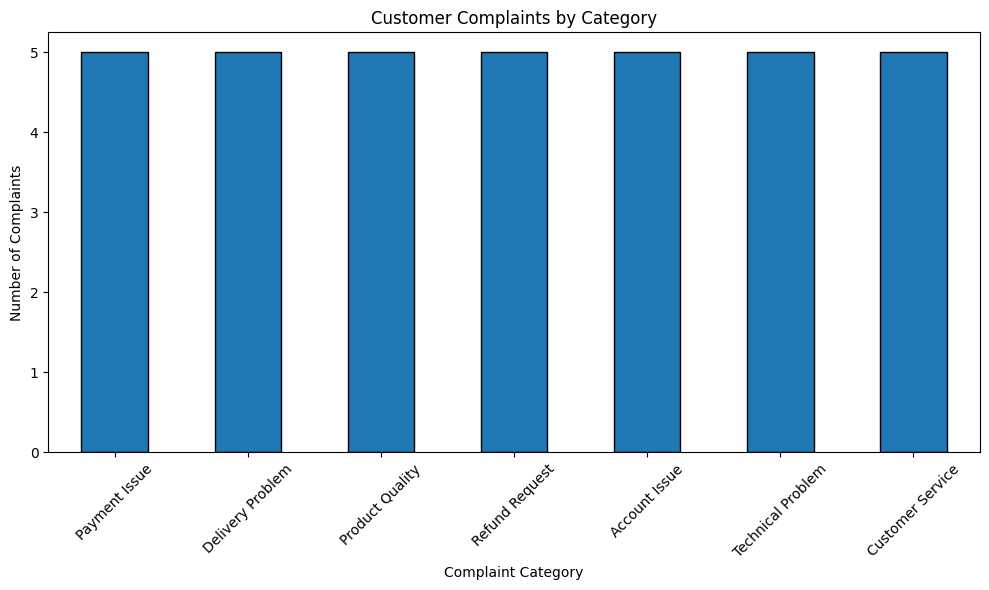

In [5]:
plt.figure(figsize=(10, 6))

df["category"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Complaints by Category")
plt.xlabel("Complaint Category")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = text.lower()

    # Remove special characters
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

df["cleaned_complaint"] = df["complaint"].apply(clean_text)

df[["complaint", "cleaned_complaint"]].head(10)

,complaint,cleaned_complaint
0,My payment was deducted but my order was not p...,payment deducted order placed
1,The money was charged twice for the same order,money charged twice order
2,I was charged but the transaction failed,charged transaction failed
3,My payment is still showing as pending,payment still showing pending
4,The payment gateway is not working,payment gateway working
5,My order has not arrived yet,order arrived yet
6,The delivery is extremely late,delivery extremely late
7,My package was supposed to arrive yesterday,package supposed arrive yesterday
8,The delivery person did not bring my package,delivery person bring package
9,My order tracking has not been updated,order tracking updated


In [7]:
!pip -q install textblob

In [8]:
from textblob import TextBlob

def get_sentiment(text):
    polarity = TextBlob(text).sentiment.polarity

    if polarity > 0.1:
        return "Positive"
    elif polarity < -0.1:
        return "Negative"
    else:
        return "Neutral"

df["sentiment"] = df["complaint"].apply(get_sentiment)

df[["complaint", "sentiment"]].head(10)

,complaint,sentiment
0,My payment was deducted but my order was not p...,Neutral
1,The money was charged twice for the same order,Neutral
2,I was charged but the transaction failed,Negative
3,My payment is still showing as pending,Neutral
4,The payment gateway is not working,Neutral
5,My order has not arrived yet,Neutral
6,The delivery is extremely late,Negative
7,My package was supposed to arrive yesterday,Neutral
8,The delivery person did not bring my package,Neutral
9,My order tracking has not been updated,Neutral


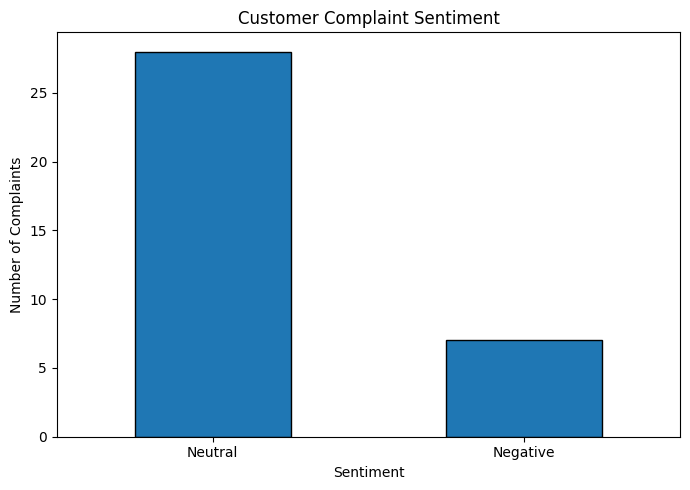

In [9]:
plt.figure(figsize=(7, 5))

df["sentiment"].value_counts().plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Complaint Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
X_text = df["cleaned_complaint"]
y = df["category"]

vectorizer = TfidfVectorizer(
    max_features=1000,
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(X_text)

print("TF-IDF matrix shape:", X.shape)

TF-IDF matrix shape: (35, 162)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 26
Testing samples: 9


In [12]:
model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [13]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 44.44 %


In [14]:
print(classification_report(y_test, y_pred))

                   precision    recall  f1-score   support

    Account Issue       1.00      1.00      1.00         1
 Customer Service       0.00      0.00      0.00         1
 Delivery Problem       0.20      1.00      0.33         1
    Payment Issue       0.00      0.00      0.00         2
  Product Quality       1.00      1.00      1.00         1
   Refund Request       0.50      1.00      0.67         1
Technical Problem       0.00      0.00      0.00         2

         accuracy                           0.44         9
        macro avg       0.39      0.57      0.43         9
     weighted avg       0.30      0.44      0.33         9



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


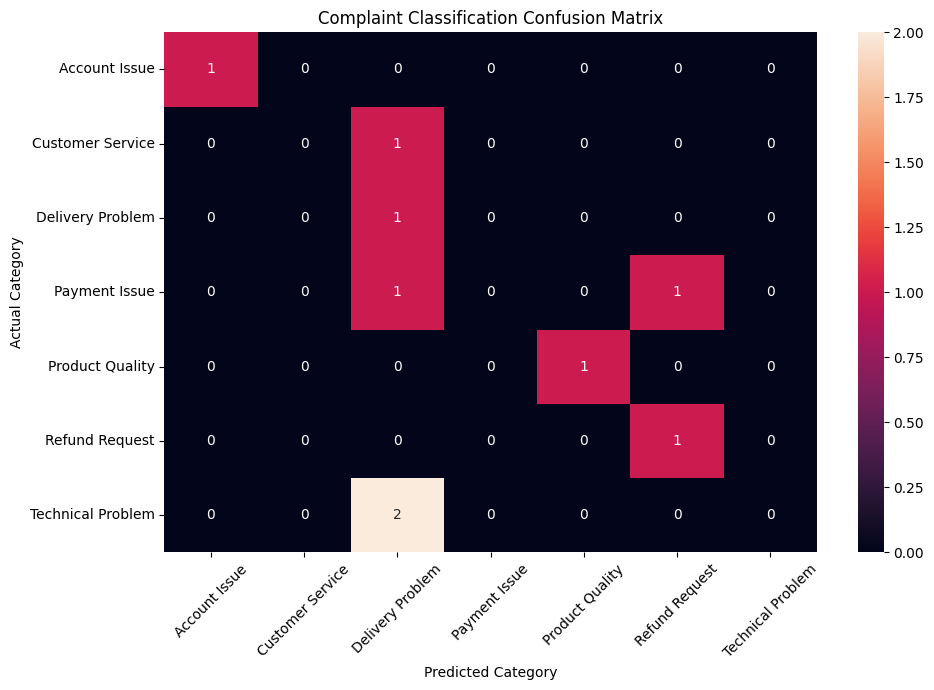

In [15]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Complaint Classification Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
def analyze_complaint(complaint):

    # Clean input
    cleaned = clean_text(complaint)

    # Convert to TF-IDF
    complaint_vector = vectorizer.transform([cleaned])

    # Predict category
    category = model.predict(complaint_vector)[0]

    # Sentiment
    sentiment = get_sentiment(complaint)

    # Priority
    urgent_words = [
        "fraud",
        "stolen",
        "blocked",
        "urgent",
        "failed",
        "charged",
        "not received",
        "cannot login"
    ]

    complaint_lower = complaint.lower()

    if any(word in complaint_lower for word in urgent_words):
        priority = "High"
    elif sentiment == "Negative":
        priority = "Medium"
    else:
        priority = "Low"

    # Department mapping
    departments = {
        "Payment Issue": "Payment Support",
        "Delivery Problem": "Delivery Team",
        "Product Quality": "Quality Team",
        "Refund Request": "Refund Department",
        "Account Issue": "Account Support",
        "Technical Problem": "Technical Support",
        "Customer Service": "Customer Support"
    }

    department = departments.get(
        category,
        "General Support"
    )

    return {
        "Category": category,
        "Sentiment": sentiment,
        "Priority": priority,
        "Department": department
    }

In [17]:
complaint = "My money was deducted but my order was not placed"

result = analyze_complaint(complaint)

print("Customer Complaint:")
print(complaint)

print("\nAnalysis Result:")

for key, value in result.items():
    print(f"{key}: {value}")

Customer Complaint:
My money was deducted but my order was not placed

Analysis Result:
Category: Payment Issue
Sentiment: Neutral
Priority: Low
Department: Payment Support


In [18]:
analyze_complaint(
    "My package is three days late and nobody is helping me"
)

{'Category': 'Delivery Problem',
 'Sentiment': 'Negative',
 'Priority': 'Medium',
 'Department': 'Delivery Team'}

In [19]:
analyze_complaint(
    "The product I received is broken and does not work"
)

{'Category': 'Product Quality',
 'Sentiment': 'Negative',
 'Priority': 'Medium',
 'Department': 'Quality Team'}

In [20]:
analyze_complaint(
    "I cannot login to my account"
)

{'Category': 'Account Issue',
 'Sentiment': 'Neutral',
 'Priority': 'High',
 'Department': 'Account Support'}

In [21]:
analyze_complaint(
    "I requested a refund but haven't received my money"
)

{'Category': 'Refund Request',
 'Sentiment': 'Neutral',
 'Priority': 'Low',
 'Department': 'Refund Department'}

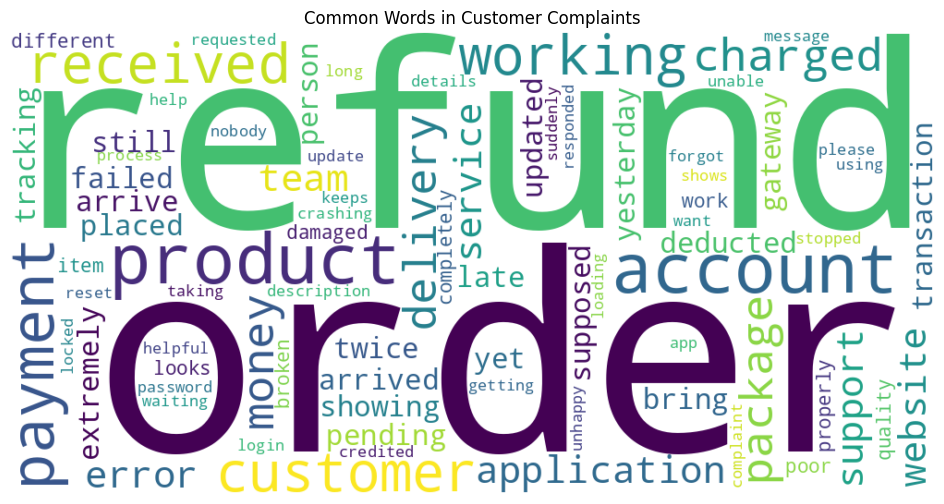

In [22]:
all_text = " ".join(df["cleaned_complaint"])

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(all_text)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Common Words in Customer Complaints")
plt.show()

In [23]:
import gradio as gr

def complaint_analyzer_interface(complaint):

    if not complaint.strip():
        return "Please enter a customer complaint."

    result = analyze_complaint(complaint)

    return f"""
Category: {result['Category']}

Sentiment: {result['Sentiment']}

Priority: {result['Priority']}

Recommended Department: {result['Department']}
"""

interface = gr.Interface(
    fn=complaint_analyzer_interface,
    inputs=gr.Textbox(
        lines=5,
        placeholder="Enter a customer complaint here..."
    ),
    outputs=gr.Textbox(
        lines=8
    ),
    title="Customer Complaint Analyzer",
    description="AI-powered complaint classification and sentiment analysis"
)

interface.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5fb8c6282683de30e2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
